# Phishing Link Detector
**Project ID:** P33 &nbsp;|&nbsp; **Name:** Ravi Suthar &nbsp;|&nbsp; **Roll no.:** H43 &nbsp;|&nbsp; **Enrollment no.:** 24004501210439 &nbsp;|&nbsp; **Division:** E

Goal: predict whether a website is **phishing (1)** or **legitimate (0)** from features of its URL and page, using a **Random Forest**.

## Step 1: Load the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay)
import warnings; warnings.filterwarnings("ignore")
print("All libraries loaded!")

All libraries loaded!


## Step 2: Load the dataset

In [2]:
df = pd.read_csv("Phishing_Legitimate_full.csv")
print(df.shape)      # (rows, columns)
df.head()

(10000, 50)


,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,...,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,CLASS_LABEL
0,1,3,1,5,72,0,0,0,0,0,...,0,0,1,1,0,1,1,-1,1,1
1,2,3,1,3,144,0,0,0,0,2,...,0,0,0,1,-1,1,1,1,1,1
2,3,3,1,2,58,0,0,0,0,0,...,0,0,0,1,0,-1,1,-1,0,1
3,4,3,1,6,79,1,0,0,0,0,...,0,0,0,1,-1,1,1,1,-1,1
4,5,3,0,4,46,0,0,0,0,0,...,1,0,0,1,1,-1,0,-1,-1,1


**Notes:** The dataset has **10,000 rows and 50 columns**: one website per row, 48 features + `id` + the target `CLASS_LABEL`.
Source: public "Phishing Legitimate" dataset (Kaggle / Mendeley Data) - *paste your link here*.

## Step 3: Understand the data

In [3]:
df.info()                   # column names, types, non-null counts
df.describe()               # min, max, mean of number columns
print(df.isnull().sum().sum(), "missing values in total")
print("Duplicates:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  10000 non-null  int64  
 1   NumDots                             10000 non-null  int64  
 2   SubdomainLevel                      10000 non-null  int64  
 3   PathLevel                           10000 non-null  int64  
 4   UrlLength                           10000 non-null  int64  
 5   NumDash                             10000 non-null  int64  
 6   NumDashInHostname                   10000 non-null  int64  
 7   AtSymbol                            10000 non-null  int64  
 8   TildeSymbol                         10000 non-null  int64  
 9   NumUnderscore                       10000 non-null  int64  
 10  NumPercent                          10000 non-null  int64  
 11  NumQueryComponents                  10000 non-null  i

### Data dictionary
| Column(s) | Meaning | Type | Keep / Drop |
|---|---|---|---|
| `id` | Row number | number | **Drop** (identifier) |
| `NumDots`, `SubdomainLevel`, `PathLevel`, `UrlLength`, `NumDash`, `NumDashInHostname`, `NumUnderscore`, `NumPercent`, `NumQueryComponents`, `NumAmpersand`, `NumHash`, `NumNumericChars` | Counts of dots, dashes, query parts, digits etc. in the URL, and its depth/length | number (count) | Keep |
| `HostnameLength`, `PathLength`, `QueryLength`, `NumSensitiveWords` | Length of each URL part; number of sensitive words in the URL | number | Keep |
| `AtSymbol`, `TildeSymbol`, `NoHttps`, `RandomString`, `IpAddress`, `DomainInSubdomains`, `DomainInPaths`, `HttpsInHostname`, `DoubleSlashInPath`, `EmbeddedBrandName` | 1 if the URL has that suspicious pattern, else 0 | number (0/1) | Keep |
| `PctExtHyperlinks`, `PctExtResourceUrls`, `PctNullSelfRedirectHyperlinks` | Share of links/resources pointing to other domains or to nowhere | number (0 to 1) | Keep |
| `ExtFavicon`, `InsecureForms`, `RelativeFormAction`, `ExtFormAction`, `AbnormalFormAction`, `FrequentDomainNameMismatch`, `FakeLinkInStatusBar`, `RightClickDisabled`, `PopUpWindow`, `SubmitInfoToEmail`, `IframeOrFrame`, `MissingTitle`, `ImagesOnlyInForm` | 1 if the web page shows that behaviour, else 0 | number (0/1) | Keep |
| `SubdomainLevelRT`, `UrlLengthRT`, `PctExtResourceUrlsRT`, `AbnormalExtFormActionR`, `ExtMetaScriptLinkRT`, `PctExtNullSelfRedirectHyperlinksRT` | Rule-coded versions (-1 / 0 / 1) of related features | number | Keep |
| `CLASS_LABEL` | **Target:** 0 = Legitimate, 1 = Phishing | number (0/1) | Target (Y) |

**What I noticed:** (1) every column is already numeric and there are no missing values, so no text encoding is really needed;
(2) the 48 features are pre-extracted from the URL and page, so the model does not read the raw web address.

## Step 4: Prepare the target column (Y)

In [4]:
TARGET = "CLASS_LABEL"
print(df[TARGET].value_counts())                  # how many rows in each class
print(df[TARGET].value_counts(normalize=True))    # same, as percentages

CLASS_LABEL
1    5000
0    5000
Name: count, dtype: int64
CLASS_LABEL
1    0.5
0    0.5
Name: proportion, dtype: float64


**Notes:** Class 0 (legitimate) = 5,000 rows and class 1 (phishing) = 5,000 rows, i.e. **50 % / 50 %. The data is balanced**,
so accuracy can be trusted, but I still focus on **Recall for phishing** because a missed phishing site is the costly mistake.

## Step 5: Clean the data

In [5]:
df = df.drop_duplicates()

# Drop the ID column (identifier, not a website feature)
df = df.drop(columns=["id"])

for col in df.columns:
    if col == TARGET: continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())     # number column -> median
    else:
        df[col] = df[col].fillna(df[col].mode()[0])    # text column -> most common value
df = df.dropna(subset=[TARGET])

print(df.isnull().sum().sum(), "missing values left")
print(df.shape)

0 missing values left
(10000, 49)


**Notes:**
- **Duplicates:** removed with `drop_duplicates()` (0 were found, the data was already unique).
- **`id` dropped:** it is only a row number and would tell the model nothing real about a website.
- **Missing values:** the median/mode code is kept as a safety step, but nothing was filled because there were 0 missing values.
- Final shape: **10,000 rows x 49 columns**.

## Step 6: Explore the data with charts (EDA)

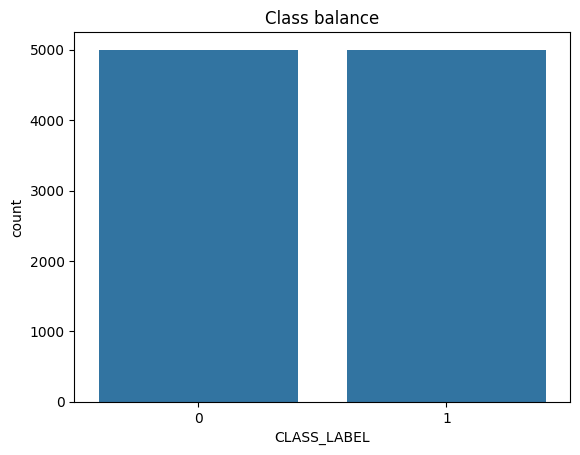

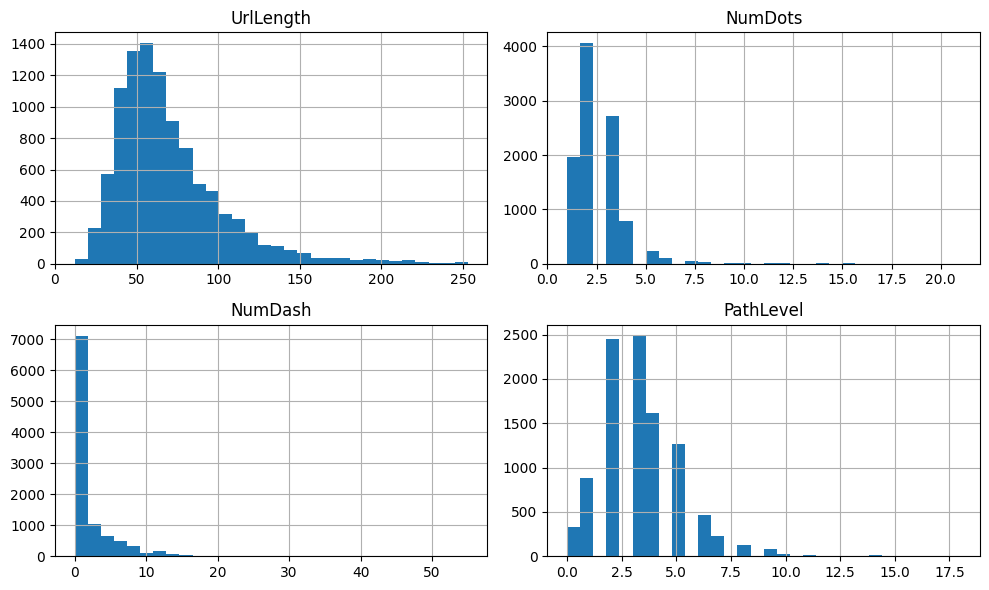

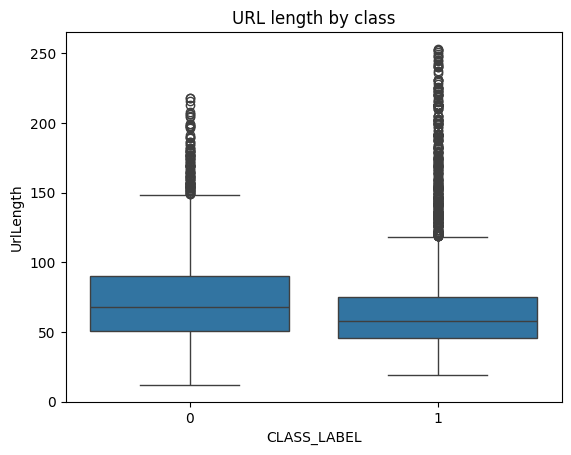

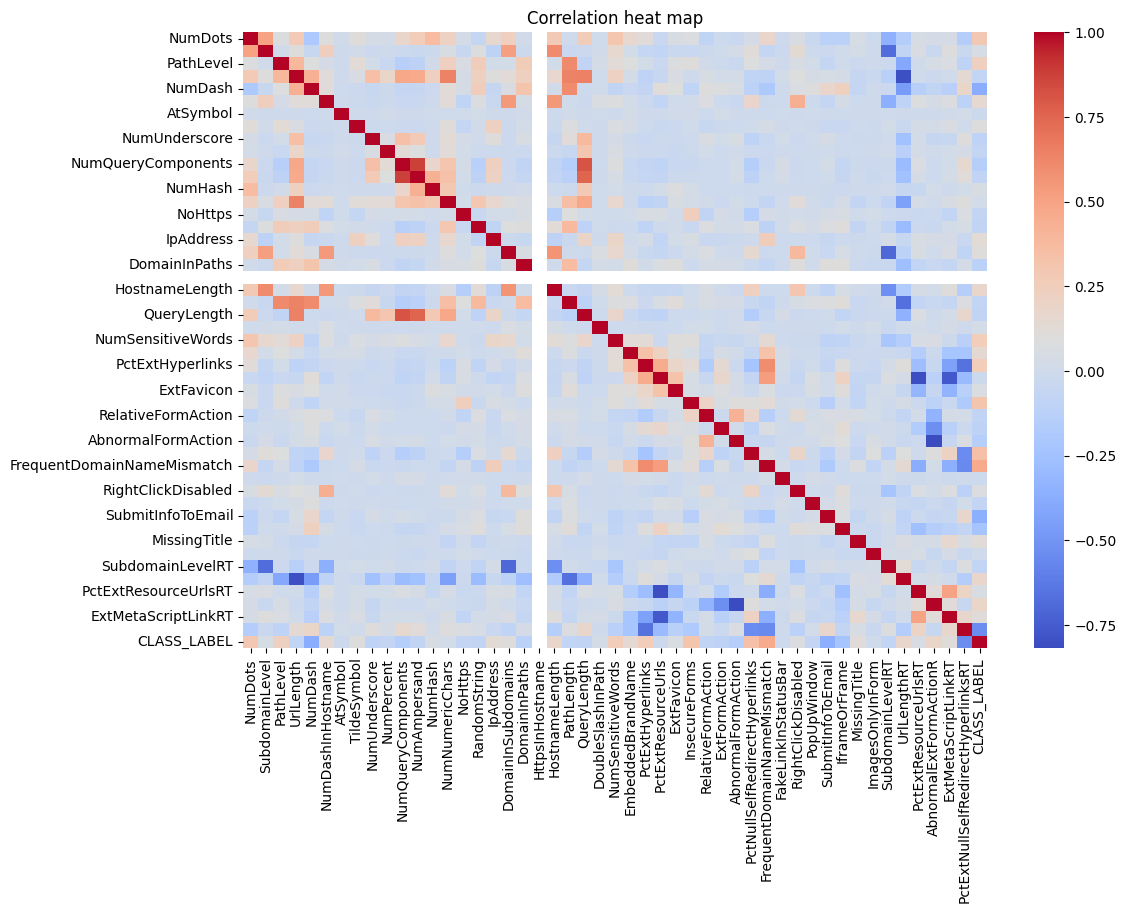

In [6]:
sns.countplot(x=df[TARGET]); plt.title("Class balance"); plt.show()

df[["UrlLength", "NumDots", "NumDash", "PathLevel"]].hist(figsize=(10, 6), bins=30); plt.tight_layout(); plt.show()

sns.boxplot(x=df[TARGET], y=df["UrlLength"]); plt.title("URL length by class"); plt.show()

num_cols = df.select_dtypes(include="number").columns
plt.figure(figsize=(12, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm"); plt.title("Correlation heat map"); plt.show()

### 5 insights
1. **Balanced classes:** exactly 5,000 phishing and 5,000 legitimate sites.
2. **Skewed counts:** `NumDots`, `UrlLength`, `NumDash` are right-skewed: most sites have small values and a few have very large ones.
3. **URL length is not a clear sign:** phishing URLs have a *lower* median length (58 vs 68) but a longer tail (max 253 vs 218).
4. **Page behaviour beats URL text:** the features most linked to the label are `PctExtNullSelfRedirectHyperlinksRT` (-0.54), `FrequentDomainNameMismatch` (+0.46) and `NumDash` (-0.37). Surprisingly, legitimate sites use *more* dashes.
5. **Useless / repeated columns:** `HttpsInHostname` has the same value in every row (blank in the heat map), and `NumQueryComponents`, `NumAmpersand` and `QueryLength` move together.

## Step 7: New feature, encoding and feature selection

In [7]:
# 1) NEW FEATURE: how complex the domain name is (more dots + deeper subdomain = more suspicious)
df["DomainComplexity"] = df["NumDots"] + df["SubdomainLevel"]

# 2) Separate X (inputs) and y (target)
X = df.drop(columns=[TARGET])
le_y = LabelEncoder()
y = le_y.fit_transform(df[TARGET])
print("Classes:", le_y.classes_)

# 3) ENCODING: one-hot encode text columns (this data has none, so the shape does not change)
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

# 4) FEATURE SELECTION (filter method): keep the 15 most useful columns
k = min(15, X.shape[1])
selector = SelectKBest(f_classif, k=k).fit(X, y)
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(scores.head(20))
X = X[scores.head(k).index]
feature_names = list(X.columns)
print("Selected:", feature_names)

Classes: [0 1]
(10000, 49)
PctExtNullSelfRedirectHyperlinksRT    4127.232733
FrequentDomainNameMismatch            2742.448014
NumDash                               1608.132123
SubmitInfoToEmail                     1466.317863
PctNullSelfRedirectHyperlinks         1331.384975
InsecureForms                         1112.073987
NumDots                                946.736097
PctExtHyperlinks                       723.239761
NumSensitiveWords                      696.548355
IframeOrFrame                          585.639947
DomainComplexity                       569.708682
PathLevel                              555.621595
AbnormalExtFormActionR                 357.484550
UrlLengthRT                            295.789232
HostnameLength                         294.510457
NumDashInHostname                      231.530069
NumQueryComponents                     222.019905
AbnormalFormAction                     214.944639
EmbeddedBrandName                      205.127249
IpAddress              

**New feature:** `DomainComplexity = NumDots + SubdomainLevel`. A phishing domain often has many dots and sub-domains (like `paypal.secure.login.example.com`), so combining them gives one stronger signal.

**Selected 15 features:** see the output above (`SelectKBest` with the ANOVA F-test).

## Step 8: Split into train and test

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(8000, 15) (2000, 15)


**Notes:** Train set = **8,000 rows**, test set = **2,000 rows** (80 / 20, `stratify=y` keeps 50 % phishing in both). Random Forest needs no scaling.

## Step 9: Train the model - Random Forest (baseline)

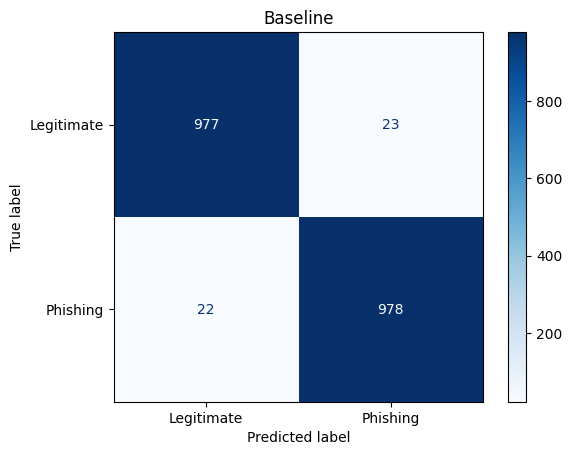

              precision    recall  f1-score   support

  Legitimate       0.98      0.98      0.98      1000
    Phishing       0.98      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



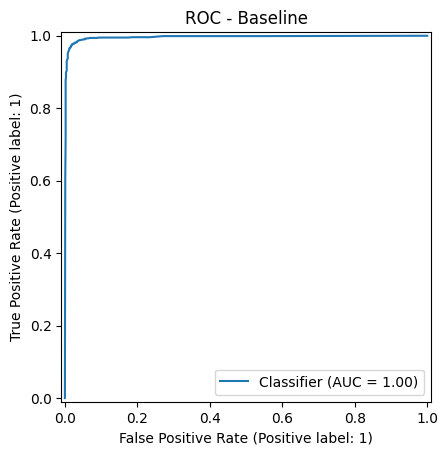

Baseline {'Accuracy': 0.9775, 'Precision': 0.977, 'Recall': 0.978, 'F1': 0.9775, 'Specificity': 0.977, 'AUC': 0.996}


In [13]:
results = []     # every setting you try is stored here

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    row = {"Setting": name,
           "Accuracy": accuracy_score(y_test, y_pred),
           "Precision": precision_score(y_test, y_pred),
           "Recall": recall_score(y_test, y_pred),
           "F1": f1_score(y_test, y_pred),
           "Specificity": tn / (tn + fp),
           "AUC": roc_auc_score(y_test, proba)}
    if show:
        ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Phishing"]).plot(cmap="Blues")
        plt.title(name); plt.show()
        print(classification_report(y_test, y_pred, target_names=["Legitimate", "Phishing"]))
        RocCurveDisplay.from_predictions(y_test, proba); plt.title("ROC - " + name); plt.show()
    print(name, {k: round(float(v), 4) for k, v in row.items() if k != "Setting"})
    return row

# BASELINE: default settings
model = RandomForestClassifier(random_state=42)
results.append(evaluate("Baseline", model, show=True))

**Baseline result:** accuracy **97.75 %**, precision 97.7 %, recall **97.8 %**, AUC **0.996**.
Confusion matrix in words: of the 2,000 test websites **1,955 were classified correctly** (977 legitimate + 978 phishing) and only **45 were wrong**:
23 legitimate sites were wrongly called phishing (false alarms) and 22 phishing sites were missed (false negatives).

## Step 10: Try different settings (tuning)

n_estimators=50 {'Accuracy': 0.976, 'Precision': 0.976, 'Recall': 0.976, 'F1': 0.976, 'Specificity': 0.976, 'AUC': 0.9963}
n_estimators=100 {'Accuracy': 0.9775, 'Precision': 0.977, 'Recall': 0.978, 'F1': 0.9775, 'Specificity': 0.977, 'AUC': 0.996}
n_estimators=200 {'Accuracy': 0.9775, 'Precision': 0.9751, 'Recall': 0.98, 'F1': 0.9776, 'Specificity': 0.975, 'AUC': 0.9959}
max_depth=5 {'Accuracy': 0.9605, 'Precision': 0.9484, 'Recall': 0.974, 'F1': 0.961, 'Specificity': 0.947, 'AUC': 0.9924}
max_depth=10 {'Accuracy': 0.9735, 'Precision': 0.974, 'Recall': 0.973, 'F1': 0.9735, 'Specificity': 0.974, 'AUC': 0.9954}


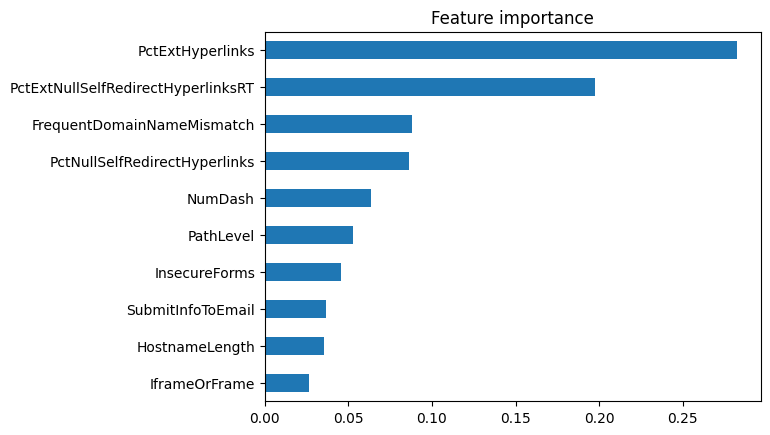

NumDash                               0.063347
PctNullSelfRedirectHyperlinks         0.085974
FrequentDomainNameMismatch            0.088310
PctExtNullSelfRedirectHyperlinksRT    0.197293
PctExtHyperlinks                      0.282420
dtype: float64


In [10]:
# A) Number of trees
for n in [50, 100, 200]:
    results.append(evaluate(f"n_estimators={n}", RandomForestClassifier(n_estimators=n, random_state=42)))

# B) max_depth  (None = no limit is the default, already tested in A with n_estimators=100)
for d in [5, 10]:
    results.append(evaluate(f"max_depth={d}", RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42)))

# C) Feature importance
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
imp.tail(10).plot(kind="barh"); plt.title("Feature importance"); plt.show()
print(imp.tail(5))

**What changed:**
- **Number of trees:** 50 trees gave 97.6 % accuracy; 100 and 200 trees gave 97.75 %. 200 trees had the best recall (98.0 %). More trees help only a little.
- **max_depth:** limiting depth hurt: depth 5 gave 96.05 % accuracy (and many more false alarms) and depth 10 gave 97.35 %. Unlimited depth (97.75 %) was best, because the trees need depth to capture the rules.

**Top 5 features in plain words** (see the chart above): the share of links that point to *other websites* (`PctExtHyperlinks`), the coded version of empty/self-redirect links (`PctExtNullSelfRedirectHyperlinksRT`), a mismatch between the page's domain name and its links (`FrequentDomainNameMismatch`), the share of empty or self-redirecting links (`PctNullSelfRedirectHyperlinks`) and the number of dashes (`NumDash`). A phishing page mostly links away to other sites and its content does not match its own domain.

**Why a forest is more stable than one tree:** one tree can memorise noise and changes a lot if the data changes a little. A forest trains many different trees on random samples of rows and columns and takes a majority vote, so individual mistakes cancel out.

## Step 11: Compare all settings and pick the final model

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline,0.978,0.977,0.978,0.978,0.977,0.996
1,n_estimators=50,0.976,0.976,0.976,0.976,0.976,0.996
2,n_estimators=100,0.978,0.977,0.978,0.978,0.977,0.996
3,n_estimators=200,0.978,0.975,0.980,0.978,0.975,0.996
4,max_depth=5,0.960,0.948,0.974,0.961,0.947,0.992
5,max_depth=10,0.974,0.974,0.973,0.973,0.974,0.995


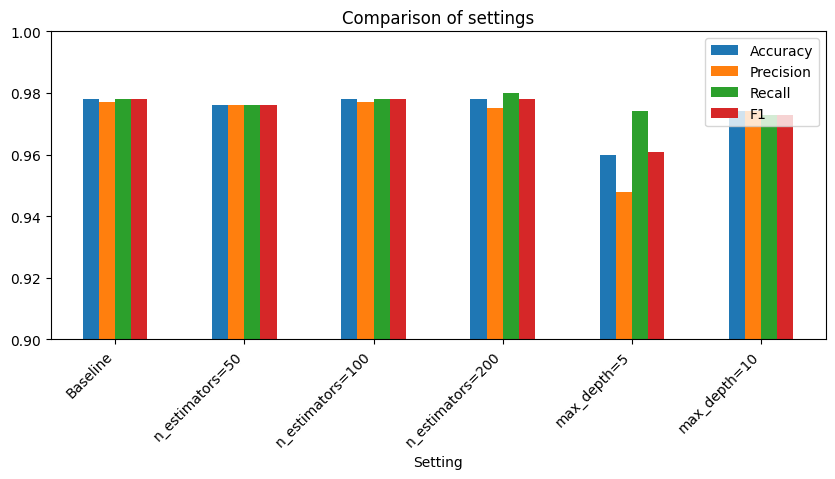

Best setting by Recall: n_estimators=200


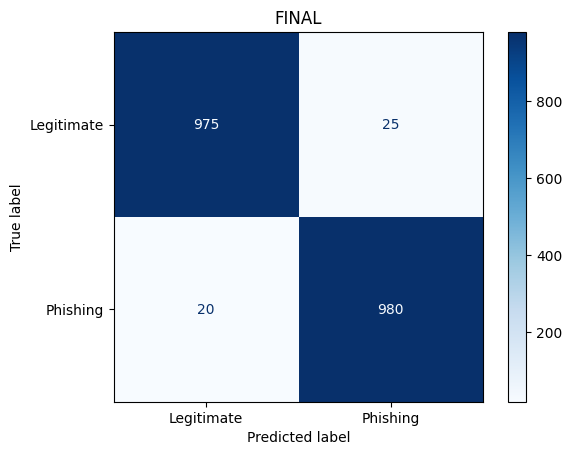

              precision    recall  f1-score   support

  Legitimate       0.98      0.97      0.98      1000
    Phishing       0.98      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



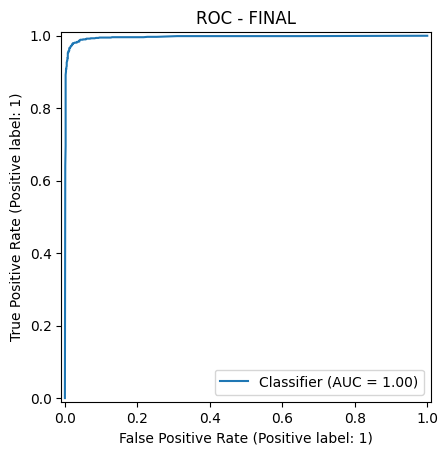

FINAL {'Accuracy': 0.9775, 'Precision': 0.9751, 'Recall': 0.98, 'F1': 0.9776, 'Specificity': 0.975, 'AUC': 0.9959}


In [11]:
res = pd.DataFrame(results).round(3)
display(res)                                    # comparison table

res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4))
plt.title("Comparison of settings"); plt.ylim(0.9, 1); plt.xticks(rotation=45, ha="right"); plt.show()

best = res.sort_values("Recall", ascending=False).iloc[0]
print("Best setting by Recall:", best["Setting"])

# FINAL MODEL: best setting by Recall
final_model = RandomForestClassifier(n_estimators=200, random_state=42)
final_row = evaluate("FINAL", final_model, show=True)



**Why this final setting:** `n_estimators=200` (no depth limit) has the **highest Recall for phishing (98.0 %)**, catching 980 of the 1,000 phishing sites in the test set (only 20 missed).
For a security tool a missed phishing site is worse than a false alarm, so Recall decides. It also keeps accuracy at 97.75 % and AUC at 0.996.
(The y-axis of the bar chart starts at 0.9 so small differences are visible.)

## Step 12: Predict 3 new inputs

In [12]:
# 3 new realistic websites, written by feature name
site1 = dict(NumDots=4, PathLevel=5, NumDash=0, HostnameLength=28, NumSensitiveWords=2, PctExtHyperlinks=0.80,
             InsecureForms=1, PctNullSelfRedirectHyperlinks=0.60, FrequentDomainNameMismatch=1, SubmitInfoToEmail=0,
             IframeOrFrame=0, UrlLengthRT=1, AbnormalExtFormActionR=1, PctExtNullSelfRedirectHyperlinksRT=-1, DomainComplexity=5)
site2 = dict(NumDots=2, PathLevel=2, NumDash=3, HostnameLength=14, NumSensitiveWords=0, PctExtHyperlinks=0.10,
             InsecureForms=1, PctNullSelfRedirectHyperlinks=0.00, FrequentDomainNameMismatch=0, SubmitInfoToEmail=0,
             IframeOrFrame=1, UrlLengthRT=0, AbnormalExtFormActionR=1, PctExtNullSelfRedirectHyperlinksRT=1, DomainComplexity=2)
site3 = dict(NumDots=3, PathLevel=3, NumDash=1, HostnameLength=20, NumSensitiveWords=0, PctExtHyperlinks=0.30,
             InsecureForms=1, PctNullSelfRedirectHyperlinks=0.10, FrequentDomainNameMismatch=0, SubmitInfoToEmail=0,
             IframeOrFrame=0, UrlLengthRT=0, AbnormalExtFormActionR=1, PctExtNullSelfRedirectHyperlinksRT=0, DomainComplexity=3)

new = pd.DataFrame([site1, site2, site3])[feature_names]     # same columns/order as training data
display(new)
pred = final_model.predict(new)
print("Predictions:", le_y.inverse_transform(pred))
print("P(phishing):", final_model.predict_proba(new)[:, 1].round(2))

,PctExtNullSelfRedirectHyperlinksRT,FrequentDomainNameMismatch,NumDash,SubmitInfoToEmail,PctNullSelfRedirectHyperlinks,InsecureForms,NumDots,PctExtHyperlinks,NumSensitiveWords,IframeOrFrame,DomainComplexity,PathLevel,AbnormalExtFormActionR,UrlLengthRT,HostnameLength
0,-1,1,0,0,0.6,1,4,0.8,2,0,5,5,1,1,28
1,1,0,3,0,0.0,1,2,0.1,0,1,2,2,1,0,14
2,0,0,1,0,0.1,1,3,0.3,0,0,3,3,1,0,20


Predictions: [1 0 0]
P(phishing): [0.98 0.   0.12]


| Site | Predicted | P(phishing) | Does it make sense? |
|---|---|---|---|
| 1 | **Phishing** | 0.98 | Yes: 4 dots, 80 % of links go to other sites, many empty links and a domain-name mismatch are all phishing signs. |
| 2 | **Legitimate** | 0.00 | Yes: short domain, uses dashes, very few outside links (dashes were more common in legitimate sites). |
| 3 | **Legitimate** | 0.12 | Yes, but less sure: medium values on everything and no domain mismatch, so it leans legitimate. |

## Step 13: Conclusion

- **What the model can do:** given 15 URL/page features, it tells phishing sites from legitimate ones. The final Random Forest (200 trees) reached **97.75 % accuracy, 98.0 % recall, 97.5 % precision and AUC 0.996** on 2,000 unseen websites, with only 45 mistakes (25 false alarms, 20 missed phishing sites).
- **What drives it:** page behaviour (links to other domains, domain-name mismatch, empty links) matters more than how the URL text looks.
- **What I learned:** tree depth matters much more than the number of trees; for security the right metric is Recall, not only accuracy; EDA and feature importance explain *why* the model decides what it decides.
- **Limits:** only one split and one algorithm were used; the 419 rows that repeat once `id` is removed may appear in both train and test; features are pre-extracted, so a real tool would first need to compute them from a live page.